# **Previsão de Churn (Abandono) em Telecom (STAB (de Kailane))**

# 1. Inicialização e importação de bibliotecas

In [87]:
import sys

def in_colab():
    return 'google.colab' in sys.modules

In [88]:
if in_colab():
    !pip install optuna
    !git clone https://github.com/kailanefelix/stab-redes-neurais.git
    !pip install keras4torch
    !pip install einops

fatal: destination path 'stab-redes-neurais' already exists and is not an empty directory.


In [89]:
import os
if in_colab():
  os.chdir("stab-redes-neurais")
else:
  %cd stab-redes-neurais-main
if os.path.exists("STAB"):
  os.rename("STAB", "STab")

In [90]:
# Sistema e utilitários
import os
import gc
from copy import deepcopy
from datetime import datetime
import random
import json

# Bibliotecas principais
import numpy as np
import pandas as pd
import optuna

# Matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Circle, Rectangle

# Scikit-learn
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils import shuffle
from sklearn.metrics import accuracy_score
from sklearn.metrics import log_loss, mean_squared_error
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import precision_recall_curve

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# Keras4Torch
import keras4torch
from keras4torch.callbacks import ModelCheckpoint, LRScheduler, EarlyStopping

# STab
import STab
from STab import *
from STab import mainmodel, LWTA, Gsoftmax

In [91]:
if in_colab():
  os.chdir("..")
else:
  %cd ..

# 2. Importando banco de dados


In [92]:
# Importar banco de dados
if in_colab():
    data = pd.read_csv("customer_churn_telecom_services.csv")
else:
    data = pd.read_csv("../customer_churn_telecom_services.csv")
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# 3. Dividindo dados

In [93]:
def separa_classe(df_class):
    df_class = shuffle(df_class, random_state=42)

    n = len(df_class)
    train = df_class.iloc[:int(0.5*n)]
    val   = df_class.iloc[int(0.5*n):int(0.75*n)]
    test  = df_class.iloc[int(0.75*n):]

    return train, val, test


def balanceamento(df_maior, df_menor):
    df_menor_bal = df_menor.sample(n=len(df_maior), replace=True, random_state=42)
    return df_menor_bal


def junta_e_mistura(df_x, df_y):
  return shuffle(pd.concat([df_x, df_y]), random_state=42)

In [94]:
# Separar classes
# Classe 0 = Churn no
# Classe 1 = Churn yes
data_cl0 = data[data["Churn"] == "No"]
data_cl1 = data[data["Churn"] == "Yes"]

# Para cada classe, separar treino(50%), validação(25%) e teste(25%) de cada classe
data_cl0_train, data_cl0_val, data_cl0_test = separa_classe(data_cl0)
data_cl1_train, data_cl1_val, data_cl1_test = separa_classe(data_cl1)

# Balancear os dados de treino e validação da classe 2 até ter mesma quantidade que os da classe 1
data_cl1_train = balanceamento(data_cl0_train, data_cl1_train)
data_cl1_val = balanceamento(data_cl0_val, data_cl1_val)


# Embaralhar dados de treino, validação e teste
data_train = junta_e_mistura(data_cl0_train, data_cl1_train)
data_val = junta_e_mistura(data_cl0_val, data_cl1_val)
data_test = junta_e_mistura(data_cl0_test, data_cl1_test)

In [95]:
print("Tamanhos finais:")
print("Treino:", data_train.shape)
print("Validação:", data_val.shape)
print("Teste:", data_test.shape)

Tamanhos finais:
Treino: (5174, 20)
Validação: (2586, 20)
Teste: (1762, 20)


# 4. Tratamento de dados

In [96]:
# ===============================
# Funções de pré-processamento
# ===============================
def treat_missing(df):
    df = df.copy()

    # Strings vazias ou só espaços → NaN
    df = df.replace(r"^\s*$", np.nan, regex=True)

    print("Linhas removidas:", df.isna().any(axis=1).sum())

    # Remove linhas com qualquer NaN
    df = df.dropna().reset_index(drop=True)

    return df


def fix_inconsistencies(df):
    df = df.copy()

    # 1. TotalCharges (string -> numeric)
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

    return df


def treating_data(df):
    df = df.copy()

    # ===============================
    # 1. Binárias Yes / No (TODAS)
    # ===============================
    yes_no_cols = [
        "Partner", "Dependents", "PhoneService",
        "PaperlessBilling", "MultipleLines",
        "OnlineSecurity", "OnlineBackup",
        "DeviceProtection", "TechSupport",
        "StreamingTV", "StreamingMovies"
    ]
    for col in yes_no_cols:
        if col in df.columns:
            df[col] = (df[col] == "Yes").astype(int)

    # ===============================
    # 2. Gender
    # ===============================
    df["gender"] = (df["gender"] == "Male").astype(int)

    # ===============================
    # 3. One-Hot Encoding
    # ===============================
    cat_cols = [
        "InternetService",
        "Contract",
        "PaymentMethod"
    ]
    df = pd.get_dummies(
        df,
        columns=cat_cols,
        drop_first=False,
        dtype=int
    )

    # ===============================
    # 4. Agregação de serviços (remove ruído)
    # ===============================
    service_cols = [
        "OnlineSecurity", "OnlineBackup",
        "DeviceProtection", "TechSupport",
        "StreamingTV", "StreamingMovies"
    ]

    df["num_services"] = df[service_cols].sum(axis=1)
    df.drop(columns=service_cols, inplace=True)

    return df


def new_features(df):
    # Média de cobrança mensal
    df["AvgMonthlyCharge"] = df["TotalCharges"] / (df["tenure"] + 1)

    # Cliente novo
    df["is_new_customer"] = (df["tenure"] <= 6).astype(int)

    return df

In [97]:
# 0. Copia banco de dados
tratando_train = data_train.copy()
tratando_val = data_val.copy()
tratando_test = data_test.copy()

In [98]:
#1. Trata dados faltando:
tratando_train = treat_missing(tratando_train)
tratando_val = treat_missing(tratando_val)
tratando_test = treat_missing(tratando_test)

Linhas removidas: 6
Linhas removidas: 2
Linhas removidas: 3


In [99]:
# 2. Muda target de "Yes"/"No" para 1/0:
tratando_train["Churn"] = (tratando_train["Churn"] == "Yes").astype(int)
tratando_val["Churn"] = (tratando_val["Churn"] == "Yes").astype(int)
tratando_test["Churn"] = (tratando_test["Churn"] == "Yes").astype(int)

In [100]:
# 3. Fix Inconsistências
tratando_train = fix_inconsistencies(tratando_train)
tratando_val = fix_inconsistencies(tratando_val)
tratando_test = fix_inconsistencies(tratando_test)

In [101]:
# 4. Tratando dados:
tratando_train = treating_data(tratando_train)
tratando_val = treating_data(tratando_val)
tratando_test = treating_data(tratando_test)

In [102]:
# 5. Add novas features:
tratando_train = new_features(tratando_train)
tratando_val = new_features(tratando_val)
tratando_test = new_features(tratando_test)

In [103]:
# 6. Separa valores target do resto do datasets:
target = "Churn"

# - Separa valores target de treino, validação e teste:
y_train = tratando_train[target]
y_val   = tratando_val[target]
y_test  = tratando_test[target]

# - Remover os valores target dos datasets para passar ao preprocessor:
tratando_train = tratando_train.drop(columns=[target])
tratando_val = tratando_val.drop(columns=[target])
tratando_test = tratando_test.drop(columns=[target])

In [104]:
# 7. Normalização
# Separa colunas entree categoricas e numericas:
cat_cols = ["InternetService", "Contract", "PaymentMethod"]
one_hot_cols = [c for c in tratando_train.columns if any(x in c for x in cat_cols)]
num_cols = [c for c in tratando_train.columns if c not in one_hot_cols + [target]]

# Cria preprocessor:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", "passthrough", one_hot_cols)
    ]
)

# Fit no treino:
preprocessor.fit(tratando_train)

# Transform no resto:
x_train = preprocessor.transform(tratando_train)
x_val   = preprocessor.transform(tratando_val)
x_test  = preprocessor.transform(tratando_test)

In [105]:
print("Formato dos dados:")
print("Dados completos:", x_train)
print("Shape:", x_train.shape)
print("Uma linha:", x_train[0])
print("Tipo:", type(x_train))

Formato dos dados:
Dados completos: [[-0.9846381  -0.48738885 -0.89481667 ...  1.          0.
   0.        ]
 [-0.9846381  -0.48738885  1.11754736 ...  0.          1.
   0.        ]
 [ 1.01560157 -0.48738885  1.11754736 ...  1.          0.
   0.        ]
 ...
 [-0.9846381  -0.48738885 -0.89481667 ...  1.          0.
   0.        ]
 [ 1.01560157  2.05174984 -0.89481667 ...  0.          1.
   0.        ]
 [ 1.01560157 -0.48738885 -0.89481667 ...  1.          0.
   0.        ]]
Shape: (5168, 23)
Uma linha: [-0.9846381  -0.48738885 -0.89481667  1.68255339 -0.61144452  0.3225486
  1.14827196  0.74858966  1.25319085 -0.33978022  1.14340129  1.0931436
 -0.61970845  0.          1.          0.          0.          1.
  0.          0.          1.          0.          0.        ]
Tipo: <class 'numpy.ndarray'>


In [106]:
# Convertendo entradas para tensores float (STab exige float32)
x_train_t = torch.tensor(x_train, dtype=torch.float32)
x_val_t = torch.tensor(x_val, dtype=torch.float32)
x_test_t  = torch.tensor(x_test,  dtype=torch.float32)

# Convertendo labels para tensores long (para classificação)
y_train_t = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_val_t   = torch.tensor(y_val.to_numpy(),   dtype=torch.long)
y_test_t  = torch.tensor(y_test.to_numpy(),  dtype=torch.long)

# Criar dataset PyTorch
train_ds = TensorDataset(x_train_t, y_train_t)
valid_ds = TensorDataset(x_val_t, y_val_t)
test_ds  = TensorDataset(x_test_t , y_test_t)

In [107]:
# Número de features numéricas no dataset
num_features = x_train.shape[1]
num_classes = len(torch.unique(y_train_t))

# 5. Hiperparametros

In [108]:
embedding_dims = [2, 4, 8]
transformes_num_limits = (1, 4)
attention_heads = [2, 4, 8]
attention_dropout = [0.10, 0.15, 0.20]
feed_foward_dropout = [0.10, 0.15, 0.20]
U_values = [2, 4]
cases_values = [8, 16]
sample_size_dims = [16, 32, 64, 128]
learning_rate_limits = (1e-4, 1e-2)
weight_decay_limits = (1e-4, 1e-2)
batch_size_values = [32, 64, 128, 256]
epochs = 10000
patience = 20
trials_optuna = 15
threshold = 0.5

# 6. Treinamento

In [109]:
def calcula_ks(y_true, y_proba, plot=False):
    # y_proba deve ser prob da classe positiva (1)
    probs = y_proba
    labels = y_true

    # Dividir probabilidades por classe
    probs_0 = np.sort(probs[labels == 0])
    probs_1 = np.sort(probs[labels == 1])

    # CDFs (acumuladas)
    cdf_0 = np.arange(1, len(probs_0) + 1) / len(probs_0)
    cdf_1 = np.arange(1, len(probs_1) + 1) / len(probs_1)

    # Emparelhamento por grade comum de thresholds
    all_probs = np.sort(np.unique(probs))
    cdf0_interp = np.interp(all_probs, probs_0, cdf_0)
    cdf1_interp = np.interp(all_probs, probs_1, cdf_1)

    # KS por diferença máxima
    ks_values = np.abs(cdf1_interp - cdf0_interp)
    ks_stat = np.max(ks_values)
    best_threshold = all_probs[np.argmax(ks_values)]

    if plot:
        # Resultados:
        print("KS Statistic:", ks_stat)
        print("Best threshold:", best_threshold)
        # Grafico:
        plt.figure(figsize=(7, 5))
        plt.plot(all_probs, cdf0_interp, label="Class 0", linewidth=2)
        plt.plot(all_probs, cdf1_interp, label="Class 1", linewidth=2)

        # Linha pontilhada do KS
        plt.plot([best_threshold, best_threshold],
                [cdf0_interp[np.argmax(ks_values)], cdf1_interp[np.argmax(ks_values)]],
                'k--', linewidth=2, label=f'KS = {ks_stat:.3f} em {best_threshold:.3f}')

        plt.title("KS Statistic Plot")
        plt.xlabel("Threshold")
        plt.ylabel("Percentage below threshold")

        plt.legend()
        plt.grid(True)
        plt.show()
    return ks_stat, best_threshold

In [110]:
def ranking_loss(probs, targets, margin=1.0):
    pos = probs[targets == 1]
    neg = probs[targets == 0]

    if len(pos) == 0 or len(neg) == 0:
        return torch.tensor(0.0, device=probs.device)

    return torch.relu(margin - (pos.mean() - neg.mean()))

def ks_friendly_loss(logits, targets):
    ce = F.cross_entropy(logits, targets)

    probs = torch.softmax(logits, dim=1)[:, 1]
    rank = ranking_loss(probs, targets)

    return ce + 0.3 * rank

In [ ]:
def cria_modelo_stab(**params):
    Or_model = mainmodel.MainModel(
        categories        = (),                             # Não temos features categóricas
        num_continuous    = num_features,                   # Número de features numéricas
        dim               = params["embedding_dimension"],  # Dimensão do embedding interno
        dim_out           = num_classes,                    # Número de classes da saída
        depth             = params["transformes_num"],      # Número de camadas Transformer
        heads             = params["attention_heads"],      # Cabeças de atenção multi-head
        attn_dropout      = params["attention_dropout"],    # Dropout dentro da atenção
        ff_dropout        = params["feed_foward_dropout"],  # Dropout no feedforward
        U                 = params["U_values"],             # Unidades vencedoras LWTA
        cases             = params["cases_values"],         # Componentes competitivos
        )

    # Wrapper para permitir treino estilo Keras
    no_model = Num_Cat(
        Or_model,
        num_number=num_features,
        classes=num_classes,
        Sample_size=params["sample_size_dims"]
    )

    model = keras4torch.Model(no_model).build([num_features])

    optimizer = torch.optim.AdamW(model.parameters(), lr=params["learning_rate"], weight_decay=params["weight_decay"])
    model.compile(
        optimizer=optimizer,
        loss=ks_friendly_loss,
        metrics=['accuracy']
        )
    return model

In [112]:
def predict_probability(model, x):
    logits = model.predict(x)                   # Saída bruta
    probas = F.softmax(torch.tensor(logits), dim=1).numpy() # Transforma em probabilidades
    return probas[:,1]

In [113]:
# Processo de treino do optuna
def objective(trial):

  # Parametros
  params = {
    "embedding_dimension": trial.suggest_categorical("embedding_dimension", embedding_dims),
    "transformes_num": trial.suggest_int("transformes_num", transformes_num_limits[0], transformes_num_limits[-1]),
    "attention_heads": trial.suggest_categorical("attention_heads", attention_heads),
    "attention_dropout": trial.suggest_categorical("attention_dropout", attention_dropout),
    "feed_foward_dropout": trial.suggest_categorical("feed_foward_dropout", feed_foward_dropout),
    "U_values": trial.suggest_categorical("U_values", U_values),
    "cases_values": trial.suggest_categorical("cases_values", cases_values),
    "sample_size_dims": trial.suggest_categorical("sample_size_dims", sample_size_dims),
    "learning_rate": trial.suggest_float("learning_rate", learning_rate_limits[0], learning_rate_limits[-1], log=True),
    "weight_decay": trial.suggest_float("weight_decay", weight_decay_limits[0], weight_decay_limits[-1], log=True),
    "batch_size": trial.suggest_categorical("batch_size", batch_size_values)
  }

  # Early Stopping
  early_stop = EarlyStopping(
    monitor='val_loss',
    patience=patience,     # quantas epochs esperar sem melhorar
    min_delta=1e-4,        # melhora mínima para contar
  )

  # Checkpoint para salvar o melhor modelo
  checkpoint = ModelCheckpoint(
    filepath='best_stab_model(treino).pth',   # arquivo que salva o modelo
    monitor='val_loss',
    save_best_only=True,
    save_weights_only=True
  )

  # Treino
  model = cria_modelo_stab(**params)
  model.fit(
    x_train_t, y_train_t,
    validation_data=(x_val_t, y_val_t),
    epochs=epochs,
    callbacks=[early_stop, checkpoint],
    verbose=1,
    batch_size=params["batch_size"]
  )

  model.load_weights('best_stab_model(treino).pth')
  pred_prob = predict_probability(model, x_val_t)

  best_ks, _  = calcula_ks(y_val_t, pred_prob)

  return best_ks

In [ ]:
# Optuna executando busca por melhores hiperparametros
#study = optuna.create_study(direction="maximize")
#study.optimize(objective, n_trials=trials_optuna)

[I 2025-12-18 18:11:21,260] A new study created in memory with name: no-name-04f3c0f4-38f9-4645-b8bc-0bb6e0477298


Train on 5168 samples, validate on 2584 samples:
Epoch 1/10000
41/41 - 3.5s - loss: 0.9569 - acc: 0.5956 - val_loss: 0.8993 - val_acc: 0.6950 - lr: 8.7e-04
Epoch 2/10000
41/41 - 3.6s - loss: 0.8774 - acc: 0.6604 - val_loss: 0.8303 - val_acc: 0.7357 - lr: 8.7e-04
Epoch 3/10000
41/41 - 3.5s - loss: 0.8178 - acc: 0.7065 - val_loss: 0.7707 - val_acc: 0.7446 - lr: 8.7e-04
Epoch 4/10000
41/41 - 3.5s - loss: 0.7802 - acc: 0.7305 - val_loss: 0.7508 - val_acc: 0.7473 - lr: 8.7e-04
Epoch 5/10000
41/41 - 3.5s - loss: 0.7599 - acc: 0.7399 - val_loss: 0.7405 - val_acc: 0.7527 - lr: 8.7e-04
Epoch 6/10000
41/41 - 3.4s - loss: 0.7568 - acc: 0.7339 - val_loss: 0.7361 - val_acc: 0.7523 - lr: 8.7e-04
Epoch 7/10000
41/41 - 3.4s - loss: 0.7496 - acc: 0.7368 - val_loss: 0.7286 - val_acc: 0.7543 - lr: 8.7e-04
Epoch 8/10000
41/41 - 3.4s - loss: 0.7431 - acc: 0.7407 - val_loss: 0.7280 - val_acc: 0.7488 - lr: 8.7e-04
Epoch 9/10000
41/41 - 3.4s - loss: 0.7346 - acc: 0.7452 - val_loss: 0.7214 - val_acc: 0.7546 - 

[I 2025-12-18 18:15:50,239] Trial 0 finished with value: 0.5281569752499791 and parameters: {'embedding_dimension': 4, 'transformes_num': 1, 'attention_heads': 2, 'attention_dropout': 0.2, 'feed_foward_dropout': 0.1, 'U_values': 2, 'cases_values': 16, 'sample_size_dims': 32, 'learning_rate': 0.000872268305317138, 'weight_decay': 0.00952469652728663, 'batch_size': 128}. Best is trial 0 with value: 0.5281569752499791.


Train on 5168 samples, validate on 2584 samples:
Epoch 1/10000
162/162 - 40s - loss: 1.0865 - acc: 0.4948 - val_loss: 1.0389 - val_acc: 0.5004 - lr: 2.1e-04
Epoch 2/10000
162/162 - 40s - loss: 1.0420 - acc: 0.5062 - val_loss: 1.0149 - val_acc: 0.5004 - lr: 2.1e-04
Epoch 3/10000
162/162 - 40s - loss: 1.0247 - acc: 0.5077 - val_loss: 0.9949 - val_acc: 0.5004 - lr: 2.1e-04
Epoch 4/10000
162/162 - 40s - loss: 1.0173 - acc: 0.5039 - val_loss: 0.9960 - val_acc: 0.4996 - lr: 2.1e-04
Epoch 5/10000
162/162 - 40s - loss: 0.9995 - acc: 0.5186 - val_loss: 0.9918 - val_acc: 0.5054 - lr: 2.1e-04
Epoch 6/10000
162/162 - 40s - loss: 0.9991 - acc: 0.5201 - val_loss: 0.9857 - val_acc: 0.5542 - lr: 2.1e-04
Epoch 7/10000
162/162 - 40s - loss: 0.9902 - acc: 0.5395 - val_loss: 0.9863 - val_acc: 0.5356 - lr: 2.1e-04
Epoch 8/10000
162/162 - 40s - loss: 0.9982 - acc: 0.5166 - val_loss: 0.9871 - val_acc: 0.5391 - lr: 2.1e-04
Epoch 9/10000
162/162 - 40s - loss: 0.9918 - acc: 0.5294 - val_loss: 0.9864 - val_acc: 

[I 2025-12-18 19:15:41,053] Trial 1 finished with value: 0.35843330532423856 and parameters: {'embedding_dimension': 2, 'transformes_num': 4, 'attention_heads': 2, 'attention_dropout': 0.2, 'feed_foward_dropout': 0.1, 'U_values': 4, 'cases_values': 16, 'sample_size_dims': 64, 'learning_rate': 0.00021242044490518293, 'weight_decay': 0.0005995591771957298, 'batch_size': 32}. Best is trial 0 with value: 0.5281569752499791.


Train on 5168 samples, validate on 2584 samples:
Epoch 1/10000
81/81 - 16s - loss: 0.9391 - acc: 0.6124 - val_loss: 0.8850 - val_acc: 0.7477 - lr: 2.7e-04
Epoch 2/10000
81/81 - 16s - loss: 0.8428 - acc: 0.6964 - val_loss: 0.8062 - val_acc: 0.7531 - lr: 2.7e-04
Epoch 3/10000
81/81 - 16s - loss: 0.7793 - acc: 0.7250 - val_loss: 0.7718 - val_acc: 0.7469 - lr: 2.7e-04
Epoch 4/10000
81/81 - 16s - loss: 0.7704 - acc: 0.7334 - val_loss: 0.7583 - val_acc: 0.7426 - lr: 2.7e-04
Epoch 5/10000
81/81 - 16s - loss: 0.7632 - acc: 0.7380 - val_loss: 0.7478 - val_acc: 0.7585 - lr: 2.7e-04
Epoch 6/10000
81/81 - 16s - loss: 0.7505 - acc: 0.7475 - val_loss: 0.7475 - val_acc: 0.7341 - lr: 2.7e-04
Epoch 7/10000
81/81 - 16s - loss: 0.7387 - acc: 0.7519 - val_loss: 0.7346 - val_acc: 0.7512 - lr: 2.7e-04
Epoch 8/10000
81/81 - 16s - loss: 0.7507 - acc: 0.7411 - val_loss: 0.7330 - val_acc: 0.7465 - lr: 2.7e-04
Epoch 9/10000
81/81 - 16s - loss: 0.7269 - acc: 0.7541 - val_loss: 0.7275 - val_acc: 0.7512 - lr: 2.7e-

... (21 outputs left out)

Train on 5168 samples, validate on 2584 samples:
Epoch 1/10000
81/81 - 11s - loss: 0.8062 - acc: 0.7028 - val_loss: 0.7365 - val_acc: 0.7399 - lr: 1.9e-03
Epoch 2/10000
81/81 - 11s - loss: 0.7349 - acc: 0.7436 - val_loss: 0.7234 - val_acc: 0.7500 - lr: 1.9e-03
Epoch 3/10000
81/81 - 11s - loss: 0.7171 - acc: 0.7539 - val_loss: 0.7111 - val_acc: 0.7550 - lr: 1.9e-03
Epoch 4/10000
81/81 - 11s - loss: 0.7060 - acc: 0.7587 - val_loss: 0.7157 - val_acc: 0.7543 - lr: 1.9e-03
Epoch 5/10000
81/81 - 11s - loss: 0.6917 - acc: 0.7610 - val_loss: 0.7109 - val_acc: 0.7454 - lr: 1.9e-03
Epoch 6/10000
81/81 - 11s - loss: 0.6774 - acc: 0.7628 - val_loss: 0.7030 - val_acc: 0.7550 - lr: 1.9e-03
Epoch 7/10000
81/81 - 11s - loss: 0.6798 - acc: 0.7620 - val_loss: 0.7029 - val_acc: 0.7562 - lr: 1.9e-03
Epoch 8/10000
81/81 - 11s - loss: 0.6738 - acc: 0.7643 - val_loss: 0.7230 - val_acc: 0.7585 - lr: 1.9e-03
Epoch 9/10000
81/81 - 11s - loss: 0.6765 - acc: 0.7651 - val_loss: 0.7037 - val_acc: 0.7457 - lr: 1.9e-

[I 2025-12-18 21:03:29,196] Trial 13 finished with value: 0.5333615570752259 and parameters: {'embedding_dimension': 8, 'transformes_num': 2, 'attention_heads': 8, 'attention_dropout': 0.1, 'feed_foward_dropout': 0.15, 'U_values': 2, 'cases_values': 8, 'sample_size_dims': 64, 'learning_rate': 0.0019221468849851835, 'weight_decay': 0.0010761800480340808, 'batch_size': 64}. Best is trial 7 with value: 0.5435874201277606.


Train on 5168 samples, validate on 2584 samples:
Epoch 1/10000
41/41 - 8.1s - loss: 0.9356 - acc: 0.6182 - val_loss: 0.8446 - val_acc: 0.7144 - lr: 4.9e-03
Epoch 2/10000
41/41 - 8.1s - loss: 0.8326 - acc: 0.7057 - val_loss: 0.7818 - val_acc: 0.7217 - lr: 4.9e-03
Epoch 3/10000
41/41 - 8.1s - loss: 0.7952 - acc: 0.7171 - val_loss: 0.7343 - val_acc: 0.7543 - lr: 4.9e-03
Epoch 4/10000
41/41 - 8.1s - loss: 0.7595 - acc: 0.7444 - val_loss: 0.7249 - val_acc: 0.7546 - lr: 4.9e-03
Epoch 5/10000
41/41 - 8.1s - loss: 0.7550 - acc: 0.7372 - val_loss: 0.7219 - val_acc: 0.7535 - lr: 4.9e-03
Epoch 6/10000
41/41 - 8.1s - loss: 0.7357 - acc: 0.7465 - val_loss: 0.7107 - val_acc: 0.7562 - lr: 4.9e-03
Epoch 7/10000
41/41 - 8.1s - loss: 0.7367 - acc: 0.7467 - val_loss: 0.7247 - val_acc: 0.7477 - lr: 4.9e-03
Epoch 8/10000
41/41 - 8.2s - loss: 0.7202 - acc: 0.7519 - val_loss: 0.7106 - val_acc: 0.7519 - lr: 4.9e-03
Epoch 9/10000
41/41 - 8.2s - loss: 0.7183 - acc: 0.7485 - val_loss: 0.7063 - val_acc: 0.7550 - 

[I 2025-12-18 21:11:04,024] Trial 14 finished with value: 0.5388858527596314 and parameters: {'embedding_dimension': 4, 'transformes_num': 3, 'attention_heads': 8, 'attention_dropout': 0.15, 'feed_foward_dropout': 0.2, 'U_values': 2, 'cases_values': 8, 'sample_size_dims': 32, 'learning_rate': 0.004882334359196745, 'weight_decay': 0.0010990085819965955, 'batch_size': 128}. Best is trial 7 with value: 0.5435874201277606.


In [ ]:
# Resultado do treino com optuna
#print("Melhores parâmetros:", study.best_params)
#print("Melhor ks:", study.best_value)

Melhores parâmetros: {'embedding_dimension': 4, 'transformes_num': 3, 'attention_heads': 2, 'attention_dropout': 0.2, 'feed_foward_dropout': 0.15, 'U_values': 2, 'cases_values': 8, 'sample_size_dims': 64, 'learning_rate': 0.00840379330955643, 'weight_decay': 0.0007537850623514248, 'batch_size': 64}
Melhor ks: 0.5435874201277606


In [128]:
# Treinamento do Modelo final usando os melhores hiperparametros
# Melhores hiperparametros:
#best_params = study.best_params
best_params = {'embedding_dimension': 4, 'transformes_num': 3, 'attention_heads': 2, 'attention_dropout': 0.2, 'feed_foward_dropout': 0.15, 'U_values': 2, 'cases_values': 8, 'sample_size_dims': 64, 'learning_rate': 0.00840379330955643, 'weight_decay': 0.0007537850623514248, 'batch_size': 64}


# Salvar em JSON
with open("best_params.json", "w") as f:
    json.dump(best_params, f, indent=4)

# Reconstruir arquitetura:
params = {
    "embedding_dimension": best_params["embedding_dimension"],
    "transformes_num": best_params["transformes_num"],
    "attention_heads": best_params["attention_heads"],
    "attention_dropout": best_params["attention_dropout"],
    "feed_foward_dropout": best_params["feed_foward_dropout"],
    "U_values": best_params["U_values"],
    "cases_values": best_params["cases_values"],
    "sample_size_dims": best_params["sample_size_dims"],
    "learning_rate": best_params["learning_rate"],
    "weight_decay": best_params["weight_decay"],
    "batch_size": best_params["batch_size"]
    }

# Cria modelo final:
final_model = cria_modelo_stab(**params)

In [129]:
#Treinamento do modelo final
# Early Stopping
early_stop = EarlyStopping(
  monitor='val_loss',
  patience=patience,     # quantas epochs esperar sem melhorar
  min_delta=1e-4,        # melhora mínima para contar
)

# Checkpoint para salvar o melhor modelo
checkpoint = ModelCheckpoint(
  filepath='best_stab_model(final).pth',   # arquivo que salva o modelo
  monitor='val_loss',
  save_best_only=True,
  save_weights_only=True
)

# Treino
final_model.fit(
  x_train_t, y_train_t,
  validation_data=(x_val_t, y_val_t),
  epochs=epochs,
  callbacks=[early_stop, checkpoint],
  verbose=1,
  batch_size=params["batch_size"]
)

# Modelo com melhor desempenho durante o treino
final_model.load_weights('best_stab_model(final).pth')

Train on 5168 samples, validate on 2584 samples:
Epoch 1/10000
81/81 - 15s - loss: 0.8336 - acc: 0.6962 - val_loss: 0.7705 - val_acc: 0.7194 - lr: 8.4e-03
Epoch 2/10000
81/81 - 15s - loss: 0.7322 - acc: 0.7508 - val_loss: 0.7369 - val_acc: 0.7334 - lr: 8.4e-03
Epoch 3/10000
81/81 - 15s - loss: 0.7310 - acc: 0.7475 - val_loss: 0.7254 - val_acc: 0.7481 - lr: 8.4e-03
Epoch 4/10000
81/81 - 15s - loss: 0.7003 - acc: 0.7622 - val_loss: 0.7231 - val_acc: 0.7434 - lr: 8.4e-03
Epoch 5/10000
81/81 - 15s - loss: 0.6960 - acc: 0.7583 - val_loss: 0.7158 - val_acc: 0.7531 - lr: 8.4e-03
Epoch 6/10000
81/81 - 15s - loss: 0.6862 - acc: 0.7670 - val_loss: 0.7148 - val_acc: 0.7543 - lr: 8.4e-03
Epoch 7/10000
81/81 - 15s - loss: 0.6833 - acc: 0.7575 - val_loss: 0.7168 - val_acc: 0.7485 - lr: 8.4e-03
Epoch 8/10000
81/81 - 15s - loss: 0.6768 - acc: 0.7663 - val_loss: 0.7053 - val_acc: 0.7577 - lr: 8.4e-03
Epoch 9/10000
81/81 - 15s - loss: 0.6678 - acc: 0.7663 - val_loss: 0.7423 - val_acc: 0.7276 - lr: 8.4e-

# 7. Analize de desempenho

In [130]:
# === 1. Obter previsões (treino, validação e teste) ===
# Treino:
y_train_proba = predict_probability(final_model, x_train_t)
y_train_pred = (y_train_proba >= threshold).astype(int)

# Validação:
y_val_proba = predict_probability(final_model, x_val_t)
y_val_pred = (y_val_proba >= threshold).astype(int)

# Teste:
y_test_proba = predict_probability(final_model, x_test_t)
y_test_pred = (y_test_proba >= threshold).astype(int)

In [131]:
# === 2. Relatórios de classificação (treino, validação, teste) ===
print("==== CLASSIFICATION REPORT - TREINO ====")
print(classification_report(y_train, y_train_pred))
print(f"Accuracy no treino: {accuracy_score(y_train_t, y_train_pred):.4f}")
print()

print("==== CLASSIFICATION REPORT - VALIDAÇÃO ====")
print(classification_report(y_val, y_val_pred))
print(f"Accuracy na validação: {accuracy_score(y_val_t, y_val_pred):.4f}")
print()

print("==== CLASSIFICATION REPORT - TESTE ====")
print(classification_report(y_test, y_test_pred))
print(f"Accuracy no teste: {accuracy_score(y_test_t, y_test_pred):.4f}")

==== CLASSIFICATION REPORT - TREINO ====
              precision    recall  f1-score   support

           0       0.81      0.72      0.76      2581
           1       0.75      0.83      0.79      2587

    accuracy                           0.78      5168
   macro avg       0.78      0.78      0.78      5168
weighted avg       0.78      0.78      0.78      5168

Accuracy no treino: 0.7769

==== CLASSIFICATION REPORT - VALIDAÇÃO ====
              precision    recall  f1-score   support

           0       0.78      0.70      0.74      1291
           1       0.73      0.80      0.76      1293

    accuracy                           0.75      2584
   macro avg       0.75      0.75      0.75      2584
weighted avg       0.75      0.75      0.75      2584

Accuracy na validação: 0.7496

==== CLASSIFICATION REPORT - TESTE ====
              precision    recall  f1-score   support

           0       0.92      0.72      0.80      1291
           1       0.51      0.82      0.63       468

In [132]:
# === 3. Precision, Recall e F1 ===
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1-Score:", f1_score(y_test, y_test_pred))

Precision: 0.512
Recall: 0.8205128205128205
F1-Score: 0.6305418719211823


In [133]:
# === 4. MSE (Erro Médio Quadrado) ===
print("MSE Treino:", mean_squared_error(y_train, y_train_pred))
print("MSE Validação:", mean_squared_error(y_val, y_val_pred))
print("MSE Teste:", mean_squared_error(y_test, y_test_pred))

MSE Treino: 0.22310371517027863
MSE Validação: 0.2503869969040248
MSE Teste: 0.2558271745309835


In [134]:
# === 5. Entropia Cruzada (Log Loss) ===
print("Log Loss Treino:", log_loss(y_train_t, y_train_proba))
print("Log Loss Validação:", log_loss(y_val_t, y_val_proba))
print("Log Loss Teste:", log_loss(y_test_t, y_test_proba))

Log Loss Treino: 0.46353364510687467
Log Loss Validação: 0.5080782791834084
Log Loss Teste: 0.5047930714677319


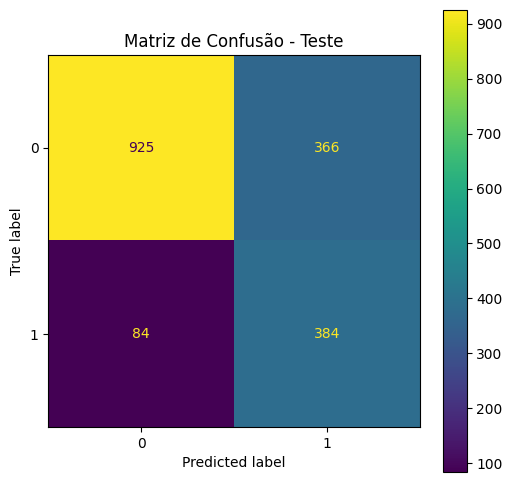

In [135]:
# === 6. Matriz de Confusão ===
fig, ax = plt.subplots(figsize=(6,6))
ConfusionMatrixDisplay.from_predictions(y_test_t, y_test_pred, ax=ax)
plt.title("Matriz de Confusão - Teste")
plt.show()

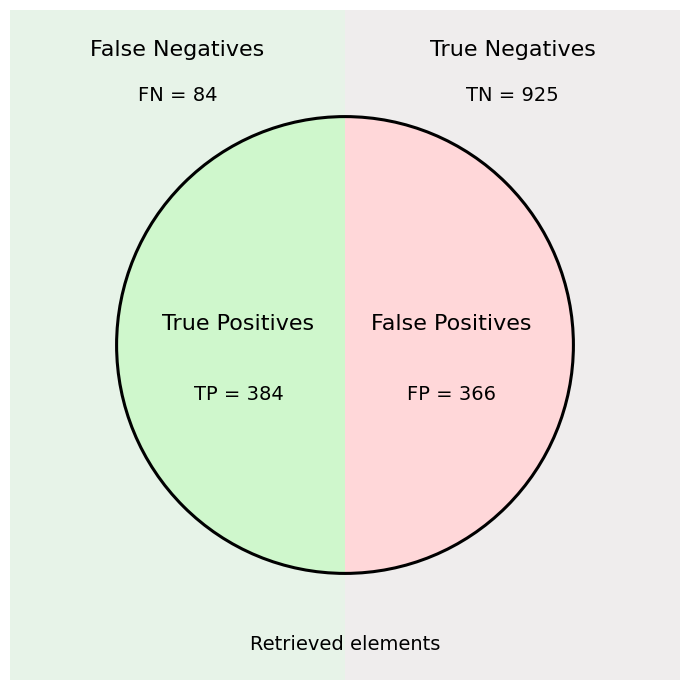

In [136]:
# === 7. Diagrama TN, FP, FN, TP ===
tn, fp, fn, tp = confusion_matrix(y_test_t, y_test_pred).ravel()

fig, ax = plt.subplots(figsize=(7,7))
ax.set_aspect('equal')
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.axis('off')

# ==========================================
# 1) FUNDOS (fora do círculo)
# ==========================================

# Esquerda (False Negatives)
bg_left  = Rectangle((-1.1, -1.1), 1.1, 2.2, facecolor='#e7f3e8', edgecolor='none', zorder=0)

# Direita (True Negatives)
bg_right = Rectangle((0.0, -1.1), 1.1, 2.2, facecolor='#efeded', edgecolor='none', zorder=0)

ax.add_patch(bg_left)
ax.add_patch(bg_right)

# ==========================================
# 2) METADE INTERNA DO CÍRCULO (TP e FP)
# ==========================================

radius = 0.75
center = (0, 0)

# TP = metade esquerda interna
tp_wedge = Wedge(center, radius, 90, 270, facecolor='#cff7cc', edgecolor='none', zorder=1)
# FP = metade direita interna
fp_wedge = Wedge(center, radius, 270, 90, facecolor='#ffd7d9', edgecolor='none', zorder=1)

ax.add_patch(tp_wedge)
ax.add_patch(fp_wedge)

# Contorno do círculo
ax.add_patch(Circle(center, radius, facecolor='none', edgecolor='black', lw=2.2, zorder=3))

# ==========================================
# 3) TEXTOS
# ==========================================

# ---- Regiões externas ----
# False Negatives (topo esquerdo)
ax.text(-0.55, 0.95, "False Negatives", fontsize=16, ha='center')
ax.text(-0.55, 0.80, f"FN = {fn}", fontsize=14, ha='center')

# True Negatives (topo direito)
ax.text(0.55, 0.95, "True Negatives", fontsize=16, ha='center')
ax.text(0.55, 0.80, f"TN = {tn}", fontsize=14, ha='center')

# ---- Regiões internas ----
ax.text(-0.35, 0.05, "True Positives", fontsize=16, ha='center')
ax.text(-0.35, -0.18, f"TP = {tp}", fontsize=14, ha='center')

ax.text( 0.35, 0.05, "False Positives", fontsize=16, ha='center')
ax.text( 0.35, -0.18, f"FP = {fp}", fontsize=14, ha='center')

# Texto inferior
ax.text(0, -1.0, "Retrieved elements", fontsize=14, ha='center')

plt.tight_layout()
plt.show()

KS Statistic: 0.5486353789303027
Best threshold: 0.5197244


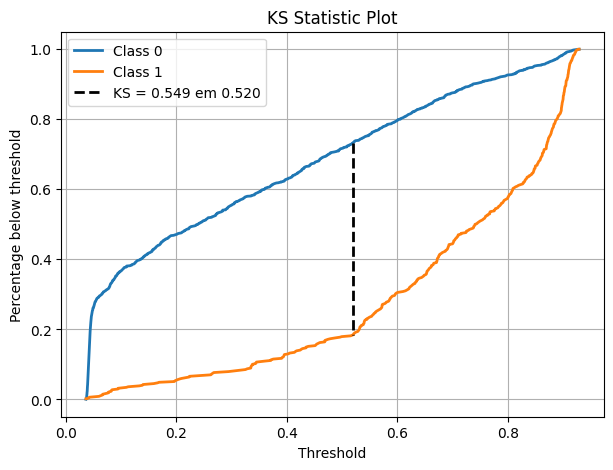

(np.float64(0.5486353789303027), np.float32(0.5197244))

In [137]:
# === 8. Teste Kolmogorov-Smirnov (KS) ===
calcula_ks(y_test_t, y_test_proba, True)

In [138]:
# === 9. AUROC ===
auc = roc_auc_score(y_test_t, y_test_proba)
print("AUC (Área sob a ROC):", auc)

AUC (Área sob a ROC): 0.8375257370222514


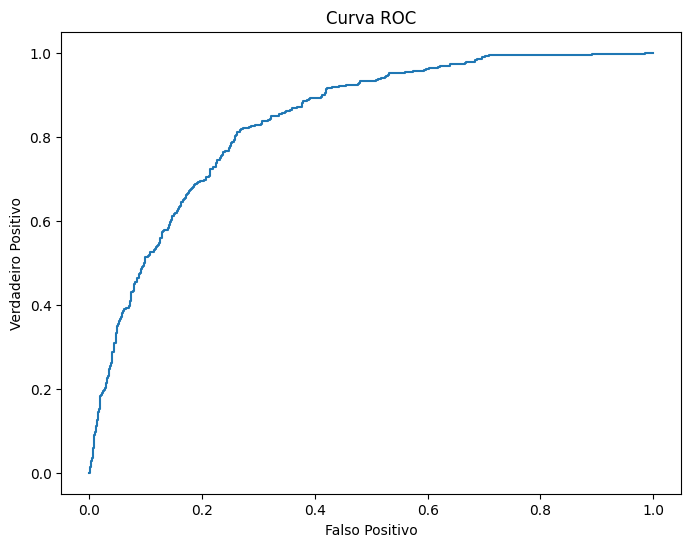

In [139]:
# === 9.5. Curva ROC ===
fpr, tpr, thresholds = roc_curve(y_test_t, y_test_proba)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr)
plt.title("Curva ROC")
plt.xlabel("Falso Positivo")
plt.ylabel("Verdadeiro Positivo")
plt.show()

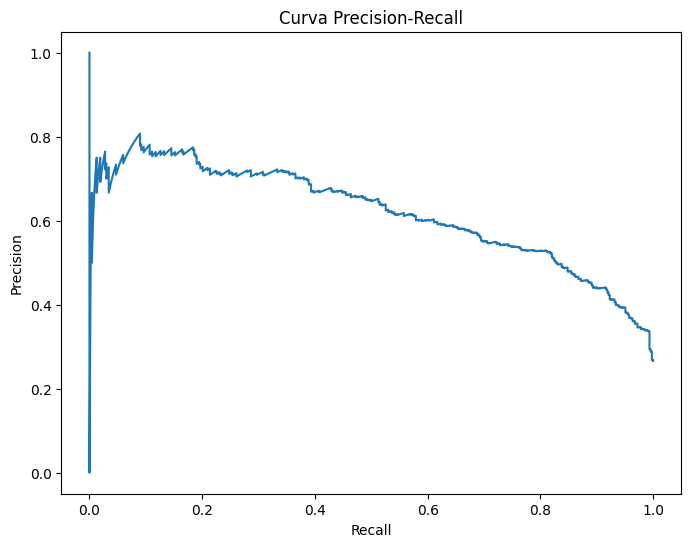

In [140]:
# === 10. Curva Precision-Recall ===
prec, rec, thr = precision_recall_curve(y_test_t, y_test_proba)
plt.figure(figsize=(8,6))
plt.plot(rec, prec)
plt.title("Curva Precision-Recall")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

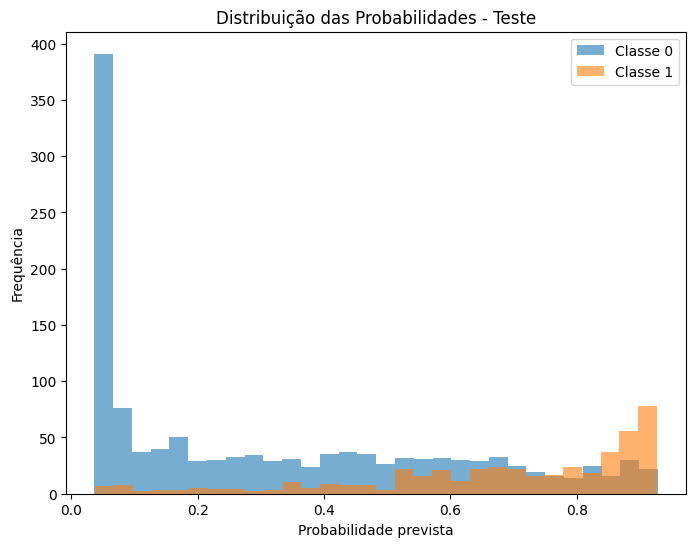

In [141]:
# === 11. Distribuição das probabilidades ===
plt.figure(figsize=(8,6))
plt.hist(y_test_proba[y_test==0], bins=30, alpha=0.6, label='Classe 0')
plt.hist(y_test_proba[y_test==1], bins=30, alpha=0.6, label='Classe 1')
plt.title("Distribuição das Probabilidades - Teste")
plt.xlabel("Probabilidade prevista")
plt.ylabel("Frequência")
plt.legend()
plt.show()